# Beijing PM2.5: Exploring air pollution patterns (2013 to 2017)

PM2.5 are tiny particles (smaller than 2.5 micrometres) that get deep into the lungs. Beijing had some of the worst PM2.5 levels in the world in this period.
The WHO guideline for a 24-hour average is **15 µg/m³** and China's own daily limit (Grade II) is **75 µg/m³**.

**Questions in this notebook**
1. How bad is the pollution and how often does it break the limits?
2. Is there a trend, a seasonal pattern or a daily pattern?
3. Which weather conditions go with clean air and polluted air?
4. Is the series stationary (important for ARIMA in the next notebook)?

**Data:** [UCI Beijing Multi-Site Air Quality](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data), hourly readings from 12 monitoring stations, March 2013 to February 2017.
I averaged the 12 stations to get one city-wide value per hour (see `00_data_preparation.ipynb`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

CHINA_LIMIT = 75   # China Grade II 24-hour limit (µg/m³)
WHO_LIMIT = 15     # WHO 2021 24-hour guideline (µg/m³)

## 1. Load the data

In [2]:
hourly = pd.read_csv("../data/beijing_hourly_city.csv", parse_dates=["datetime"], index_col="datetime")
print(hourly.shape)
hourly.head()

(35064, 12)


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
datetime,,,,,,,,,,,,
2013-03-01 00:00:00,5.67,7.92,5.67,12.60,308.33,75.42,-0.92,1022.77,-19.90,0.00,4.18,NNW
2013-03-01 01:00:00,6.83,9.83,5.33,12.00,308.33,75.75,-1.22,1023.19,-19.92,0.00,3.88,NW
2013-03-01 02:00:00,5.67,7.25,6.38,11.91,300.00,66.00,-1.59,1023.32,-21.01,0.00,4.40,NNW
2013-03-01 03:00:00,6.00,9.25,5.83,11.52,300.00,66.12,-1.89,1024.21,-21.83,0.00,3.37,NW
2013-03-01 04:00:00,4.83,6.92,6.75,11.89,308.33,66.33,-2.28,1024.87,-21.62,0.00,2.72,N


In [3]:
# make a daily series: average of the 24 hours (rain is summed)
daily = hourly.drop(columns="wd").resample("D").mean()
daily["RAIN"] = hourly["RAIN"].resample("D").sum()
pm25 = daily["PM2.5"]

print("Days:", len(daily))
print("Missing values:", daily.isnull().sum().sum())
pm25.describe()

Days: 1461
Missing values: 0


count   1461.00
mean      79.84
std       67.26
min        5.43
25%       31.79
50%       61.31
75%      106.30
max      473.05
Name: PM2.5, dtype: float64

## 2. How bad is the pollution?

In [4]:
above_china = (pm25 > CHINA_LIMIT).mean() * 100
above_who = (pm25 > WHO_LIMIT).mean() * 100
print(f"Average daily PM2.5: {pm25.mean():.1f} µg/m³ (about {pm25.mean() / WHO_LIMIT:.1f}x the WHO guideline)")
print(f"Days above China's limit (75): {above_china:.1f}%")
print(f"Days above WHO guideline (15): {above_who:.1f}%")
print(f"Worst day: {pm25.idxmax().date()} with {pm25.max():.0f} µg/m³")

Average daily PM2.5: 79.8 µg/m³ (about 5.3x the WHO guideline)
Days above China's limit (75): 40.5%
Days above WHO guideline (15): 92.1%
Worst day: 2015-12-01 with 473 µg/m³


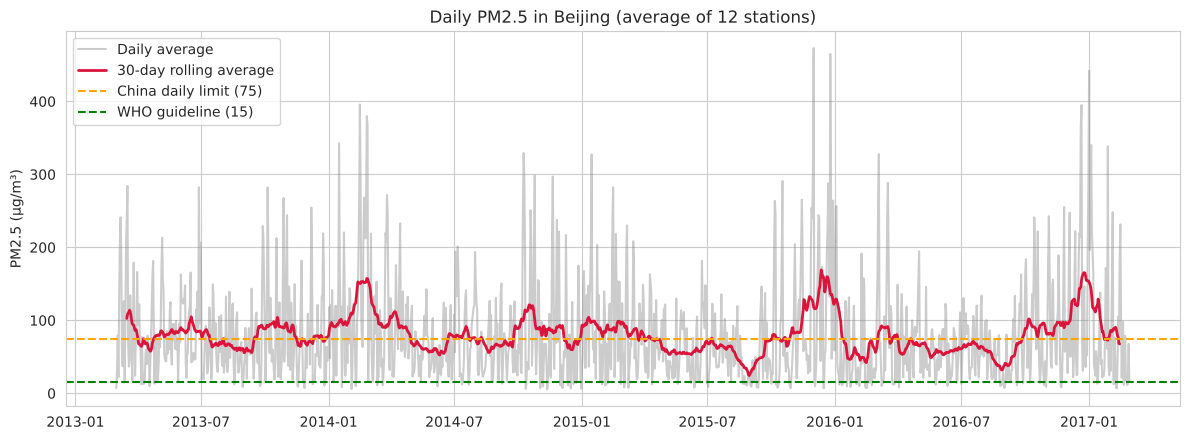

In [5]:
plt.figure(figsize=(12, 4.5))
plt.plot(pm25, alpha=0.4, color="grey", label="Daily average")
plt.plot(pm25.rolling(30, center=True).mean(), color="crimson", linewidth=2, label="30-day rolling average")
plt.axhline(CHINA_LIMIT, color="orange", linestyle="--", label="China daily limit (75)")
plt.axhline(WHO_LIMIT, color="green", linestyle="--", label="WHO guideline (15)")
plt.title("Daily PM2.5 in Beijing (average of 12 stations)")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../images/01_daily_pm25.png", dpi=150)
plt.show()

The series has big spikes (pollution episodes) mostly in winter, and lower levels in summer.
There is no clear long-term downward trend over these four years.

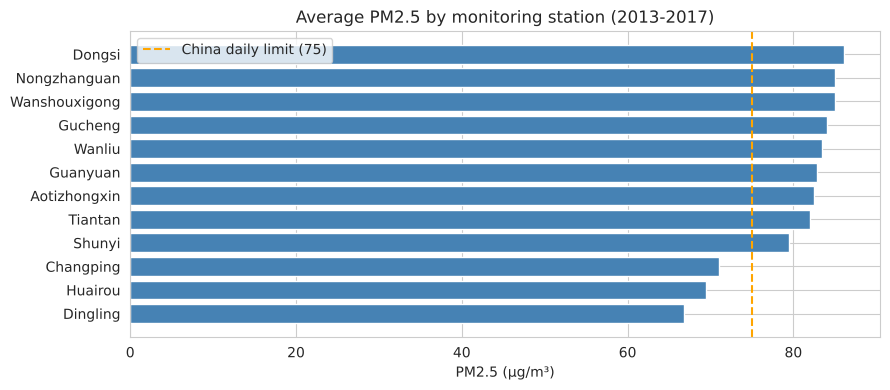

Correlation between stations (average): 0.94


In [6]:
# average PM2.5 at each of the 12 stations
stations = pd.read_csv("../data/station_daily_pm25.csv", parse_dates=["datetime"], index_col="datetime")
station_avg = stations.mean().sort_values()

plt.figure(figsize=(9, 4))
plt.barh(station_avg.index, station_avg.values, color="steelblue")
plt.axvline(CHINA_LIMIT, color="orange", linestyle="--", label="China daily limit (75)")
plt.title("Average PM2.5 by monitoring station (2013-2017)")
plt.xlabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.savefig("../images/01b_station_average.png", dpi=150)
plt.show()

print("Correlation between stations (average):", round(stations.corr().values[np.triu_indices(12, 1)].mean(), 2))

All 12 stations are polluted and move together very closely (high correlation), so one city-wide average is a fair summary.
The rural stations in the north (Dingling, Huairou) are the cleanest; the city centre is the worst.

## 3. Seasonal and daily patterns

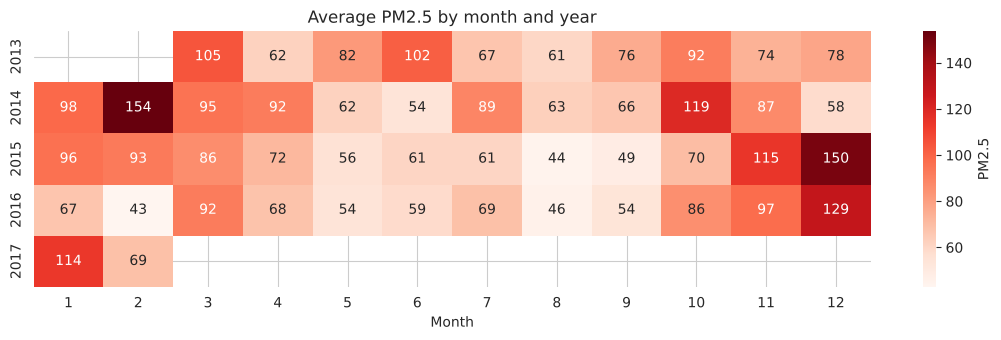

In [7]:
# year x month heatmap of average PM2.5
daily["year"] = daily.index.year
daily["month"] = daily.index.month
heat = daily.pivot_table(index="year", columns="month", values="PM2.5", aggfunc="mean")

plt.figure(figsize=(11, 3.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "PM2.5"})
plt.title("Average PM2.5 by month and year")
plt.xlabel("Month")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/02_month_year_heatmap.png", dpi=150)
plt.show()

In [8]:
seasons = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
daily["season"] = daily["month"].map(seasons)

season_table = daily.groupby("season")["PM2.5"].agg(["mean", "median"])
season_table["% days above 75"] = daily.groupby("season")["PM2.5"].apply(lambda s: (s > CHINA_LIMIT).mean() * 100)
season_table.loc[["Winter", "Spring", "Summer", "Autumn"]]

,mean,median,% days above 75
season,,,
Winter,95.74,67.33,45.43
Spring,77.21,62.42,41.30
Summer,64.52,54.00,35.05
Autumn,82.21,61.55,40.38


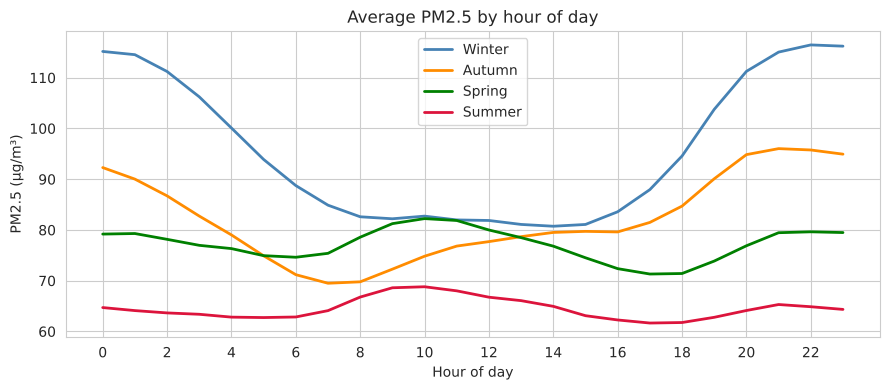

In [9]:
# hour of day profile, winter vs summer (uses the hourly data)
hourly["hour"] = hourly.index.hour
hourly["season"] = hourly.index.month.map(seasons)
profile = hourly.groupby(["season", "hour"])["PM2.5"].mean().unstack(0)

plt.figure(figsize=(9, 4))
for s, colour in [("Winter", "steelblue"), ("Autumn", "darkorange"), ("Spring", "green"), ("Summer", "crimson")]:
    plt.plot(profile.index, profile[s], label=s, color=colour, linewidth=2)
plt.title("Average PM2.5 by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.tight_layout()
plt.savefig("../images/03_hour_of_day.png", dpi=150)
plt.show()

Pollution builds up through the evening and peaks around 10 to 11 pm, especially in winter (heating plus a low, cold air layer at night that traps the particles).
In winter it is lowest in the early afternoon, when the sun warms the ground and the air mixes more.

## 4. Weather and pollution

In [10]:
weather_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
daily[["PM2.5"] + weather_cols].corr()["PM2.5"].drop("PM2.5").sort_values()

WSPM   -0.43
TEMP   -0.16
RAIN   -0.04
PRES    0.04
DEWP    0.08
Name: PM2.5, dtype: float64

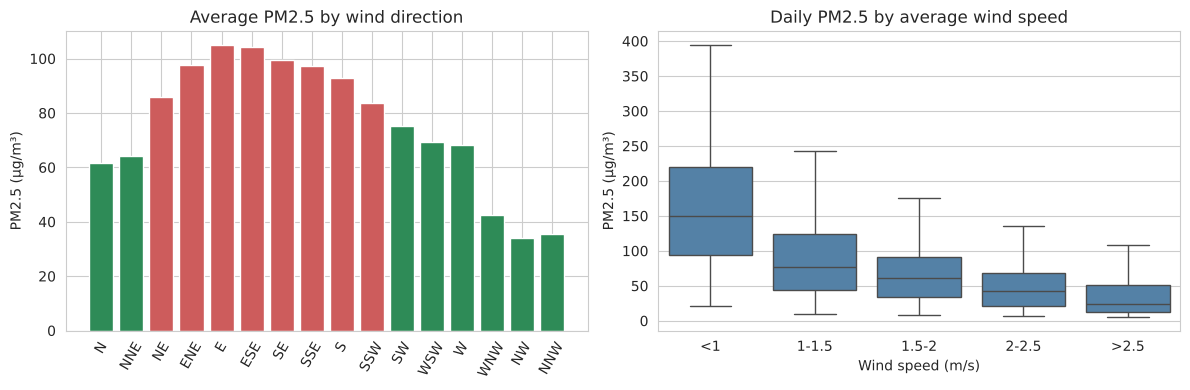

In [11]:
# PM2.5 by wind direction (hourly data)
wind_order = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
wind_pm = hourly.groupby("wd")["PM2.5"].mean().reindex(wind_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colours = ["seagreen" if v < hourly["PM2.5"].mean() else "indianred" for v in wind_pm.values]
axes[0].bar(wind_pm.index, wind_pm.values, color=colours)
axes[0].set_title("Average PM2.5 by wind direction")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].tick_params(axis="x", rotation=60)

# wind speed groups
daily["wind_group"] = pd.cut(daily["WSPM"], bins=[0, 1, 1.5, 2, 2.5, 10],
                             labels=["<1", "1-1.5", "1.5-2", "2-2.5", ">2.5"])
sns.boxplot(data=daily, x="wind_group", y="PM2.5", ax=axes[1], color="steelblue", showfliers=False)
axes[1].set_title("Daily PM2.5 by average wind speed")
axes[1].set_xlabel("Wind speed (m/s)")
axes[1].set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.savefig("../images/04_wind_effect.png", dpi=150)
plt.show()

In [12]:
print("Calm days (wind < 1 m/s) average PM2.5:", round(daily.loc[daily["WSPM"] < 1, "PM2.5"].mean(), 1))
print("Windy days (wind > 2.5 m/s) average PM2.5:", round(daily.loc[daily["WSPM"] > 2.5, "PM2.5"].mean(), 1))
print("North-west wind average:", round(wind_pm["NW"], 1), "| East wind average:", round(wind_pm["E"], 1))

Calm days (wind < 1 m/s) average PM2.5: 157.4
Windy days (wind > 2.5 m/s) average PM2.5: 36.2
North-west wind average: 34.2 | East wind average: 104.9


**Wind is the biggest weather factor.** Strong winds from the north and north-west bring clean air from the mountains and blow the pollution away.
Calm days and winds from the east, south-east and south (from the flat, industrial plains around Beijing) go with the worst pollution.

## 5. Is the series stationary? (needed for ARIMA)

In [13]:
result = adfuller(pm25)
print("ADF test on daily PM2.5: statistic =", round(result[0], 2), " p-value =", f"{result[1]:.2e}")

result_log = adfuller(np.log(pm25))
print("ADF test on log PM2.5:  statistic =", round(result_log[0], 2), " p-value =", f"{result_log[1]:.2e}")

ADF test on daily PM2.5: statistic = -17.44  p-value = 4.69e-30
ADF test on log PM2.5:  statistic = -22.25  p-value = 0.00e+00


/tmp/ipykernel_1020/582750978.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(pm25)
/tmp/ipykernel_1020/582750978.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_log = adfuller(np.log(pm25))


Both p-values are far below 0.05, so the series is **stationary** (no unit root). This means ARIMA does not need differencing (d = 0).
I will model **log PM2.5** because the raw values are very skewed with big spikes.

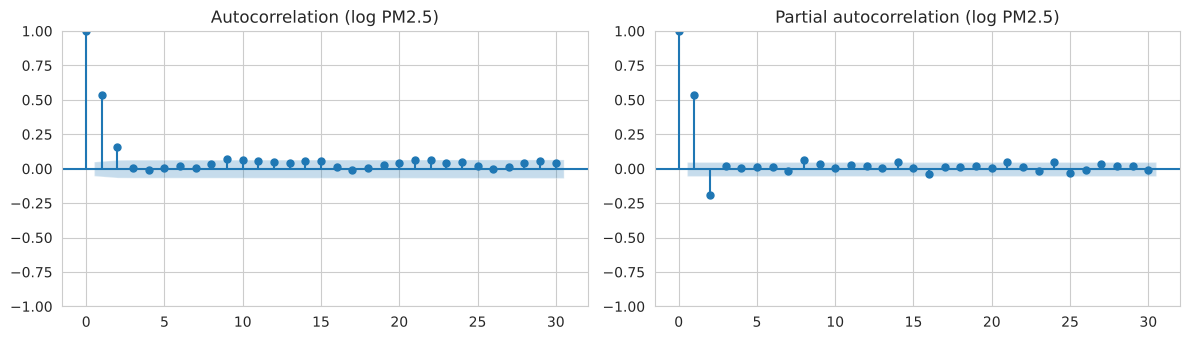

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(np.log(pm25), lags=30, ax=axes[0])
plot_pacf(np.log(pm25), lags=30, ax=axes[1], method="ywm")
axes[0].set_title("Autocorrelation (log PM2.5)")
axes[1].set_title("Partial autocorrelation (log PM2.5)")
plt.tight_layout()
plt.savefig("../images/05_acf_pacf.png", dpi=150)
plt.show()

The ACF drops quickly and the PACF has one strong spike at lag 1, so today's pollution mostly depends on yesterday's.
This suggests a small ARIMA model like AR(1) or ARMA(1,1). There is no strong weekly (lag 7) pattern.

## Summary
- Beijing's average PM2.5 was about **5x the WHO guideline**, and about 40% of days broke China's own limit.
- Winter is the worst season and pollution peaks at night.
- Low wind speed and east/south-east winds go with high pollution; north-west winds clean the air.
- The series is stationary and mostly depends on the previous day, which I use in the forecasting notebook.